##Детерминанты научной результативности российских университетов
(Артур Левда, БГИМУ246)

В современных исследованиях экономики высшего образования центральное место занимает вопрос эффективности университетов и поиска баланса между образовательной и научно-исследовательской функциями. В этой связи сохраняется интерес к факторам, определяющим научную результативность вузов, однако эмпирические исследования дают противоречивые оценки этих связей.

Эмпирическая литература не дает единого ответа на вопрос о влиянии грантовой и ресурсной обеспеченности на публикационную активность. С одной стороны, показано, что гранты в краткосрочной перспективе значительно (на 31%) повышают научный выпуск [Hussinger & Carvalho, 2021], с другой - ни количество грантов (прямого проектного финансирования), ни их доля в бюджете вуза не оказывают значимого влияния на научную эффективность, так как вуз при получении финансирования предпочитает расширить научный состав, а при его нехватке находит ресурсы из других источников [Zacharewicz et al, 2023]. Некоторые работы говорят, что публикационная активность наоборот зависит от доли доходов от научно-исследовательской и опытно-конструкторской работы (НИОКР) и умении продать исследования в целом, а не не от конкретных грантов [Sandler, 2020]. Также существует позиция, что эффект от грантов зависит от престижа вуза, при этом для непристижных вузов существует U-образная свяь между финансированием и результативностью - эффект грантов зависит от достигнутого уровня финансирования (отдача положительна только при доле бюджетного финансирования менее 49,55%, далее становится отрицательной) [Yu et al., 2022]. Существует позиция, что научная эффективность зависит от количества сотрудников с учёными степенями, а гранты сконцентрированны в местах, где таких сотрудников много [Gladyrev, 2023; Лавриненко et al, 2023].


Консенсуса нет и о влиянии качества абитуриентов в виде среднего балла ЕГЭ на научную ориентацию вуза. Одни исследования показывают умеренную положительную связь (корреляция 0,48) [Sandler, 2020], другие - незначимую [Gladyrev, 2023], а в исследовании эффективности вузов публикационная активность нарушает оценки, основанные на образовательных параметрах (в том числе баллах ЕГЭ) - без неё была гладкая гистограмма распределения по эффективности, а с ней вузы распались на группы по результативности, что говорит о несогласованности образовательной и научно-исследовательской функциях университетов [Абанкина et al, 2013].

**Гипотезы:**

H1. Научная результативность вуза зависит от его ресурсной обеспеченности, качества кадров и студентов.

H1a. Чем выше относительное количество грантов на 100 НПР, тем выше публикационная активность вуза на 100 НПР.  

Исследовательские гранты способны повышать научный выпуск, хотя эффект может зависеть от горизонта наблюдения и не всегда подтверждается для конкурентного финансирования в целом. [Hussinger & Carvalho, 2021; Zacharewicz et al, 2023]


H1b. Чем выше удельный вес доходов от НИОКР в общих доходах вуза, тем выше его публикационная активность на 100 НПР.

Для российских вузов показано, что научно-финансовая ориентация связана с публикационной активностью и другими параметрами исследовательского развития. [Sandler, 2020]

H1c. Чем выше доля НПР, имеющих ученую степень, тем выше публикационная активность вуза на 100 НПР.

Доля преподавателей с учёными степенями оказывается значимым фактором в моделях научной ориентации вузов, работы подчёркивают роль кадрового потенциала и квалификации исследователей. [Gladyrev, 2023]


H1d. Чем выше средний балл ЕГЭ абитуриентов на бюджетные места, тем выше публикационная активность вуза на 100 НПР.

Средний балл ЕГЭ выступает как индикатором качества входящего контингента и может показывать как эффективность вуза в целом с одной стороны, так и его ориентацию на образовательную, а не научно-исследовательскую деятельность с другой стороны. [Абанкина et al, 2013]

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [ ]:
df = pd.read_excel('/content/result2022.xlsx')

In [44]:
df.head(10)

,"Средний балл ЕГЭ студентов, принятых по результатам ЕГЭ на обучение по очной форме по программам бакалавриата и специалитета за счет средств соответствующих бюджетов бюджетной системы РФ","Средний балл ЕГЭ студентов университета, принятых по результатам ЕГЭ на обучение по очной форме по программам бакалавриата и специалитета за счет средств соответствующих бюджетов бюджетной системы Российской Федерации, за исключением лиц, поступивших с учетом особых прав и в рамках квоты целевого приема","Средний балл ЕГЭ студентов, принятых по результатам ЕГЭ на обучение по очной форме по программам бакалавриата и специалитета с оплатой стоимости затрат на обучение физическими и юридическими лицами","Усредненный по реализуемым направлениям (специальностям) минимальный балл ЕГЭ студентов, принятых по результатам ЕГЭ на обучение по очной форме на программы бакалавриата и специалитета","Численность студентов, победителей и призеров заключительного этапа всероссийской олимпиады школьников, членов сборных команд Российской Федерации, участвовавших в международных олимпиадах по общеобразовательным предметам по специальностям и (или) направлениям подготовки, соответствующим профилю всероссийской олимпиады школьников или международной олимпиады, принятых на очную форму обучения на первый курс по программам бакалавриата и специалитета без вступительных испытаний","Численность студентов, победителей и призеров олимпиад школьников, принятых на очную форму обучения на первый курс по программам бакалавриата и специалитета по специальностям и (или) направлениям подготовки, соответствующим профилю олимпиады школьников, без вступительных испытаний","Численность студентов, принятых по результатам целевого приема на первый курс на очную форму обучения по программам бакалавриата и специалитета","Удельный вес численности студентов, принятых по результатам целевого приема на первый курс на очную форму обучения по программам бакалавриата и специалитета в общей численности студентов, принятых на первый курс по программам бакалавриата и специалитета на очную форму обучения","Удельный вес численности студентов (приведенного контингента), обучающихся по программам магистратуры, в общей численности приведенного контингента обучающихся по образовательным программам бакалавриата, специалитета и магистратуры","Удельный вес численности обучающихся (приведенного контингента), по программам магистратуры, подготовки научно-педагогических кадров в аспирантуре (адъюнктуре), ординатуры, ассистентуры-стажировки в общей численности приведенного контингента обучающихся по основным образовательным программам высшего образования",...,Доля доходов вуза от образовательной деятельности в общих доходах вуза,Доля доходов вуза от научных исследований и разработок в общих доходах вуза,Доля внебюджетных средств в доходах от образовательной деятельности,Доля внебюджетных средств в доходах от научных исследований и разработок,VUZ,Region,Type,Site,ID,year
0,0.00,0.00,61.28,48.28,0,0,0,0.0,8.34,8.34,...,80.76,4.42,100.00,100.00,Автономная некоммерческая образовательная орга...,Воронежская область,Частные образовательные организации,http://www.vepi.ru,110170,2022
1,51.69,51.69,51.48,39.26,0,0,0,0.0,0.00,0.00,...,66.01,11.19,34.13,100.00,Автономная некоммерческая образовательная орга...,Воронежская область,Частные образовательные организации,http://www.iict.ru,1996,2022
2,0.00,0.00,0.00,0.00,0,0,0,0.0,0.00,0.00,...,97.58,0.00,100.00,0.00,Автономная некоммерческая образовательная орга...,Курская область,Частные образовательные организации,http://rfei.ru/,2071,2022
3,0.00,0.00,55.70,55.70,0,0,0,0.0,0.00,0.00,...,68.66,1.53,100.00,100.00,Автономная некоммерческая образовательная орга...,Московская область,Частные образовательные организации,https://www.pssi-k.ru/,666667486,2022
4,0.00,0.00,0.00,0.00,0,0,0,0.0,100.00,100.00,...,9.09,85.08,9.77,12.17,Автономная некоммерческая образовательная орга...,г.Москва,Частные образовательные организации,www.skoltech.ru,113493,2022
5,0.00,0.00,52.36,42.27,0,0

**Обоснование использование датасета:**

Датасет представляет собой собранные данные о 681 вузе России, отражающие их основные показатели, включая источники финансирования, научную деятельность и общую информацию. В частности, в нём представлены показатели научной эффективности, грантовой активности, доли доходов от НИОКР, характеристики студентов, кадров и масштаба образовательной деятельности. Это делает датасет пригодным для эмпирической проверки гипотез текущего исследования.

Год сбора данных: 2022.

**Концептуализация:**

Научная результативность вуза понимается как способность образовательной организации производить научные результаты в виде количества публикаций, индексируемых в РИНЦ, в расчёте на научно-педагогического работника (НПР). Этот показатель отражает интенсивность и видимость научной деятельности университета. Показатель отбалансированный на число НПР, что позволяет находить изменения в относительных, а не абсолютных значениях, а также сопоставлять вузы разного масштаба.

Грантовая активность - один из источников внешнего финансирования и механизм поддержки исследований. В логике исследования она рассматривается не только как ресурс, но и как возможный фактор организации научной работы, влияющий на научную результативность. Так как она измеряется в расчёте на НПР, то и грантовая активность также должна быть сбалансирована на число сотрудников.

Финансовая обеспеченность НИОКР отражает долю доходов, получаемых вузом от научно-исследовательских и опытно-конструкторских работ, и характеризует степень вовлеченности университета в научно-исследовательскую деятельность, ориентированную на получение контрактных результатов. Этот показатель может как демонстрировать другие источники финансирования, кроме грантов, так и сигнализировать о научно-исследовательском фокусе в вузе.

Входной академический уровень абитуриентов рассматривается через средний балл за ЕГЭ как возможный индикатор селективности и общего качества образовательной среды.

Кадровый потенциал понимается как доля НПР, имеющих ученую степень, и отражает академическую квалификацию персонала, от которой может зависеть способность вуза вести исследования и публиковать результаты.

Масштаб университета определяется общей численностью студентов и используется как контрольная переменная, позволяющая учитывать размер организации и связанные с ним ресурсы. В контексте научных исследований это может означать наличие соответствующей инфраструктуры с одной стороны и бюрократическую нагрузку и ограничения с другой.

**Операционализация:**

В датасете переменные представлены под содержательными названиями, для удобства написания кода мы переименуем их.

Зависимая переменная (a) - Число публикаций организации, индексируемых в информационно-аналитической системе научного цитирования РИНЦ, в расчете на 100 НПР

Независимые переменные:
1. b - Количество полученных грантов за отчетный год в расчете на 100 НПР
2. c - Удельный вес доходов от НИОКР в общих доходах образовательной организации
3. d - Средний балл ЕГЭ студентов, принятых по результатам ЕГЭ на обучение по очной форме по программам бакалавриата и специалитета за счет средств соответствующих бюджетов бюджетной системы РФ
4. e - Удельный вес НПР, имеющих ученую степень кандидата и доктора наук, в общей численности НПР образовательной организации (без совместителей и работающих по договорам гражданско-правового характера)
5. f - Контрольная переменная - Общая численность студентов, обучающихся по программам бакалавриата, специалитета, магистратуры

In [62]:
A1 = ['Число публикаций организации, индексируемых в информационно-аналитической системе научного цитирования РИНЦ, в расчете на 100 НПР[н]',
     'Количество полученных грантов за отчетный год в расчете на 100 НПР[н]',
     'Удельный вес доходов от НИОКР в общих доходах образовательной организации',
     'Средний балл ЕГЭ студентов, принятых по результатам ЕГЭ на обучение по очной форме по программам бакалавриата и специалитета за счет средств соответствующих бюджетов бюджетной системы РФ',
     'Удельный вес НПР, имеющих ученую степень кандидата и доктора наук, в общей численности НПР образовательной организации (без совместителей и работающих по договорам гражданско-правового характера)',
     'Общая численность студентов, обучающихся по программам бакалавриата, специалитета, магистратуры'
     ] #Список переменных для регрессии
B = ['a', 'b', 'c', 'd', 'e','f'] #Список новых названий для переменных
df1 = pd.DataFrame() #Пустой датафрейм
for i in range(6):
    df1[B[i]]=df[A1[i]] #Добавляем в пустой датафрейм поочерёдно все 6 переменных с новыми названиями

In [63]:
df1.head(10)

,a,b,c,d,e,f
0,55.17,0.00,4.42,0.00,80.00,1709
1,105.26,0.00,11.19,51.69,82.71,843
2,59.02,0.00,0.00,0.00,80.00,578
3,96.39,0.00,1.53,0.00,93.33,63
4,186.84,16.21,85.08,0.00,46.25,557
5,3378.75,0.00,1.92,0.00,90.53,2414
6,24.05,0.00,6.23,0.00,93.50,1087
7,18.49,0.00,1.43,0.00,11.56,409
8,265.92,4.68,9.14,53.50,96.18,2862
9,280.25,0.00,0.00,0.00,51.72,175


Пропущенных значений в датасете нет.
Но у вузов с отсутствующими бюджетными местами средний балл ЕГЭ по бюджетным местам равен 0, что сильно сместит оценки коэффициентов, поэтому мы будем рассматривать только вузы с бюджетными местами.

<Axes: >

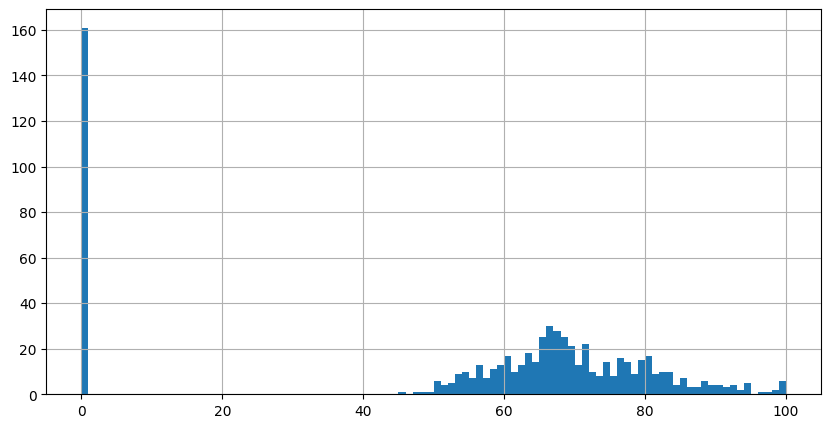

In [64]:
df1['d'].hist(bins=100, figsize=(10,5))

In [65]:
df1['d'] = df1['d'].replace(0,np.nan)
df2 = df1.dropna() #Убираем нули в переменной 'b'.
df1.shape, df2.shape

((681, 6), (520, 6))

In [66]:
df2['A']=np.log(df2['a']+1) #Логарифмируем зависимую переменную (число публикаций), что будет важно для соблюдения линейности в будущем.
#Так как количество публикаций может быть равно 0, прибавляем 1, чтобы было возможно взять логарифм

/tmp/ipykernel_11639/4235628389.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2['A']=np.log(df2['a']+1) #Логарифмируем зависимую переменную (число публикаций), что будет важно для соблюдения линейности в будущем.


In [67]:
df2.describe()

,a,b,c,d,e,f,A
count,520.000000,520.000000,520.000000,520.000000,520.000000,520.000000,520.000000
mean,370.883596,3.847981,7.610519,70.289327,71.857654,6564.936538,5.549428
std,428.684918,6.420169,7.199413,10.888199,16.733559,6217.535468,0.919948
min,0.000000,0.000000,0.000000,45.750000,3.970000,28.000000,0.000000
25%,150.420000,0.000000,2.945000,63.220000,66.217500,2167.500000,5.020056
50%,272.650000,1.705000,5.385000,68.760000,75.710000,4856.000000,5.611849
75%,456.902500,4.755000,9.500000,77.542500,83.122500,8390.500000,6.126653
max,6611.600000,62.630000,51.710000,100.000000,100.000000,37926.000000,8.796732


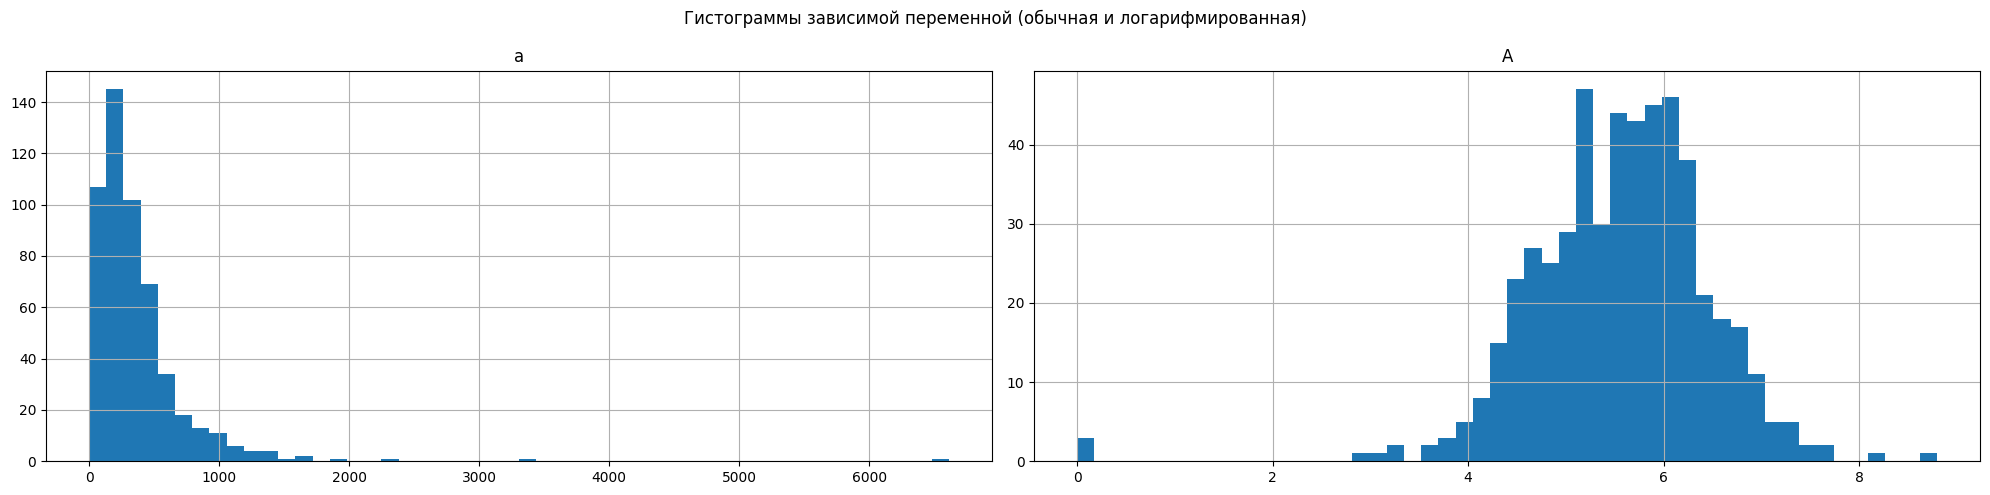

In [68]:
aA = ['a', 'A']
df2[aA].hist(bins=50, figsize=(20,5))
plt.suptitle('Гистограммы зависимой переменной (обычная и логарифмированная)')
plt.tight_layout()
plt.show()

#Гистограмма для зависимой переменной (обычной и логарифмированной). Видно, что обычное распределение асимметричное, скошенное вправо даже без учётов выбросов.
#Логарифмированная переменная более симметрична, можно использовать её для анализа для получения линейных оценок.

In [69]:
df2 = df2.drop('a', axis = 1) #Убираем переменную 'a', она нам больше не нужна

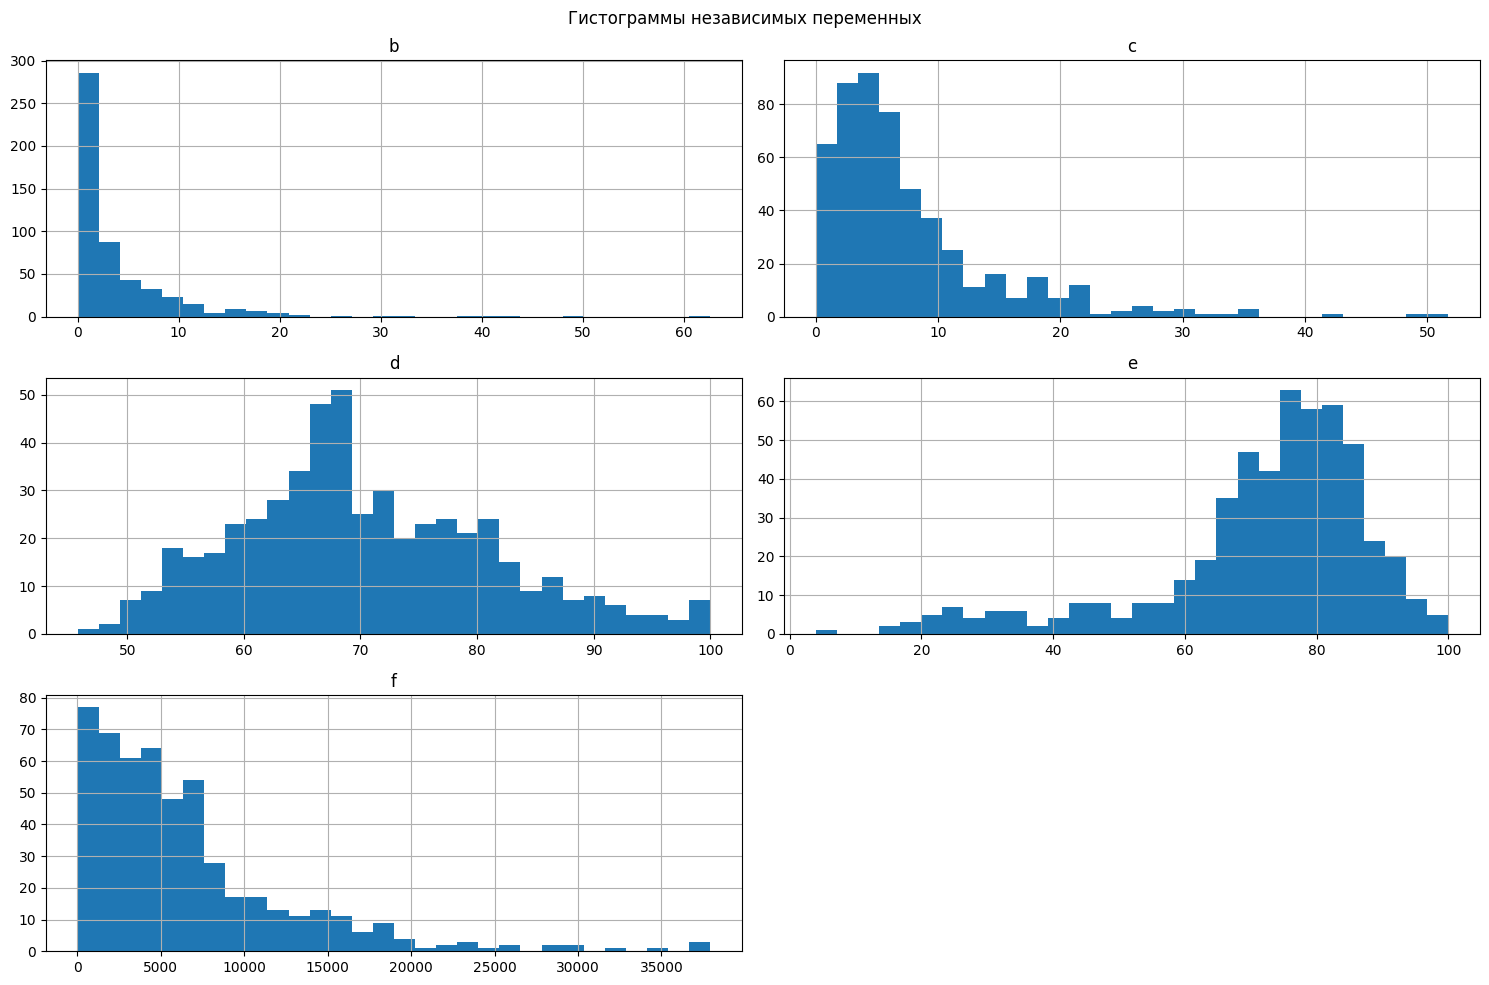

In [70]:
bcdef = ['b','c','d','e','f'] #Гистограммы всех независимых переменных
df2[bcdef].hist(bins=30, figsize=(15,10))
plt.suptitle('Гистограммы независимых переменных')
plt.tight_layout()
plt.show()
#В дальнейшем переменная f (общее число студентов) будет логарифмирована.
#Для сохранения простоты интерпретации переменные b (количество грантов на 100 НПР) и c (доля НИОКР в финансировании) логарифмированы не будут, несмотря на их асимметричность.

Корреляционная матрица Пирсона:
       b      c      d      e      f
b  1.000  0.268  0.029  0.164  0.209
c  0.268  1.000  0.201  0.074  0.300
d  0.029  0.201  1.000 -0.251  0.179
e  0.164  0.074 -0.251  1.000  0.248
f  0.209  0.300  0.179  0.248  1.000


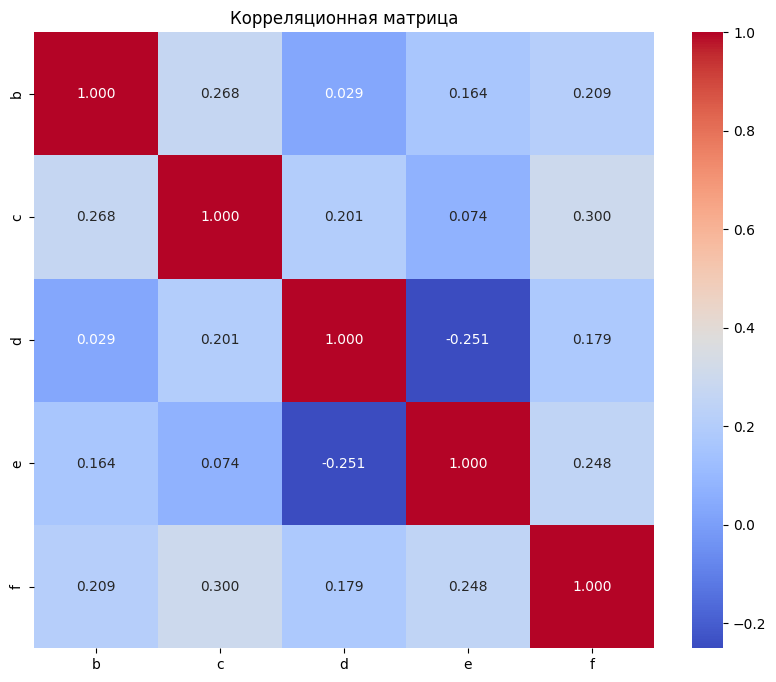

In [71]:
#Корреляции независимых переменных
cont_vars = ['b','c','d','e','f']
cm = df2[cont_vars].corr()
print('Корреляционная матрица Пирсона:')
print(cm.round(3))
plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, cmap= 'coolwarm', fmt='.3f')
plt.title('Корреляционная матрица')
plt.tight_layout
plt.show()

Все корреляции слабые, есть 1 пограничная между слабой и умеренной (0.3, между числом студентов и удельным весом доходов от НИОКР в общих доходах образовательной организации), впоследствии необходимо проверить взаимное объяснение через VIF.

In [72]:
#Логарифмируем число студентов и выбрасываем старую переменную 'f'. В анализе мы будем использовать только её логарифм
df2['F']=np.log(df2['f'])
df2 = df2.drop('f', axis = 1)
df2.head()

,b,c,d,e,A,F
1,0.00,11.19,51.69,82.71,4.665889,6.736967
8,4.68,9.14,53.50,96.18,5.586949,7.959276
10,0.00,2.81,100.00,85.21,5.476882,6.970730
13,0.00,4.10,90.90,78.04,5.528238,7.644441
17,1.45,6.85,82.04,45.45,4.201703,7.661998


In [73]:
#Уберём очень влиятельные выбросы по расстоянию Кука, которые в прошлых моделях сильно смещали оценки коэффициентов
model4 = smf.ols('A ~ b + c + d + e + F', data = df2).fit()
i = model4.get_influence()
c = i.cooks_distance[0]
t = 4 / len(df2)
print(f"Порог для меры Кука (4/n): {t:.4f}")
tc = pd.Series(c, index=df2.index).sort_values(ascending=False).head(10)
print("Топ-10 наблюдений по Cook's distance:")
print(tc)

Порог для меры Кука (4/n): 0.0077
Топ-10 наблюдений по Cook's distance:
312    0.714323
88     0.294298
31     0.208884
395    0.093123
308    0.030767
84     0.025490
330    0.020289
67     0.020240
287    0.019495
547    0.014217
dtype: float64


In [74]:
#Есть 3 наблюдения с особо большими расстояниями Кука, уберём их
df3 = df2.drop([312, 88, 31])

Спецификация - ln(количество публикаций в РИНЦ на 100 НПР) зависит от количества грантов на 100 НПР, удельного веса доходов от НИОКР, среднего балла ЕГЭ на бюджетных местах, удельного веса НПР со званием кандидата или доктора наук, ln(общее число студентов).


Выбранная спецификация позволяет проверить все гипотезы исследования.

In [75]:
model6 = smf.ols('A ~ b + c + d + e + F', data = df3).fit() #Модель множественной регрессии
print(model6.summary())

                            OLS Regression Results                            
Dep. Variable:                      A   R-squared:                       0.303
Model:                            OLS   Adj. R-squared:                  0.296
Method:                 Least Squares   F-statistic:                     44.40
Date:                Tue, 24 Mar 2026   Prob (F-statistic):           4.89e-38
Time:                        14:21:49   Log-Likelihood:                -536.75
No. Observations:                 517   AIC:                             1086.
Df Residuals:                     511   BIC:                             1111.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      4.4356      0.314     14.134      0.0

In [76]:
#Reset-тест Рамсея на линейность
from statsmodels.stats.diagnostic import het_breuschpagan, normal_ad, linear_reset
reset_test = linear_reset(model6, power=2, use_f=True)
print(reset_test)
if reset_test.pvalue > 0.05:
    print("Модель специфицирована корректно (нет пропущенных нелинейностей, p > 0.05)")
else:
    print("Модель может быть неверно специфицирована (p ≤ 0.05), возможно, нужны нелинейные члены")

<F test: F=2.426306368868505, p=0.11993404021891323, df_denom=510, df_num=1>
Модель специфицирована корректно (нет пропущенных нелинейностей, p > 0.05)


In [87]:
#Рассчёт расстояний Кука и критического расстояния
influence=model6.get_influence()
cooks = influence.cooks_distance[0]
threshold = 4 / len(df3)
print(f"Порог для меры Кука (4/n): {threshold:.4f}")
print(f"Наблюдений с Cook's distance > порога: {(cooks > threshold).sum()}")

Порог для меры Кука (4/n): 0.0077
Наблюдений с Cook's distance > порога: 26


In [88]:
#Вывод наблюдений с наибольшим расстоянием Кука
top_cooks = pd.Series(cooks, index=df3.index).sort_values(ascending=False).head(5)
print("Топ-5 наблюдений по Cook's distance:")
print(top_cooks)
#Есть среднее количество выбросов. Их удаление повышает R2 и нормальность остатков, но мешают линейности, поэтому в этой модели они сохранены (кроме 3 уже удалённых ранее выбросов).

Топ-5 наблюдений по Cook's distance:
395    0.075918
308    0.044063
330    0.025956
547    0.025816
67     0.024010
dtype: float64


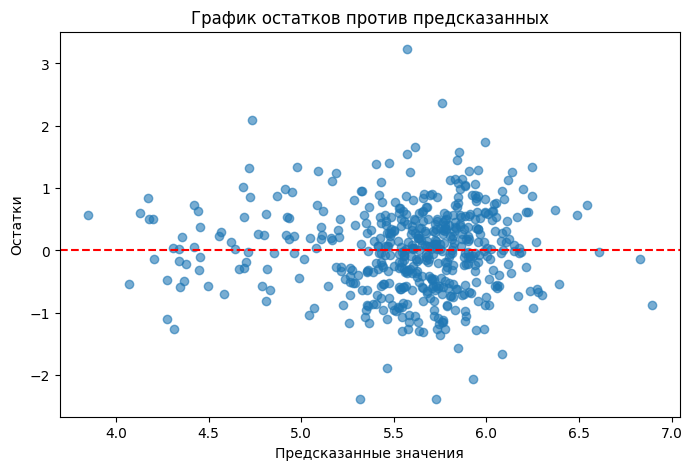

In [79]:
#График рассеивания остатков
fitted = model6.fittedvalues
residuals2 = model6.resid
plt.figure(figsize=(8,5))
plt.scatter(fitted, residuals2, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Предсказанные значения')
plt.ylabel('Остатки')
plt.title('График остатков против предсказанных')
plt.savefig('residuals_vs_fitted.png', dpi=150)
plt.show()
#Гомоскедастичность по нему неочевидна, нужна дополнительная проверка тестом Бройша-Пагана

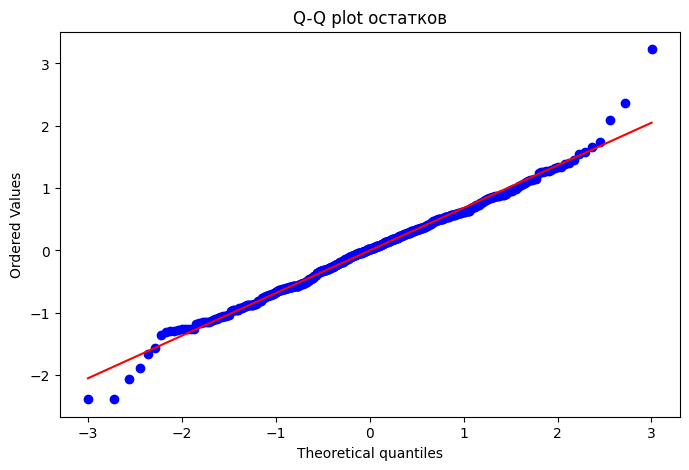

In [80]:
#Q-Q plot остатков
plt.figure(figsize=(8,5))
stats.probplot(residuals2, dist="norm", plot=plt)
plt.title('Q-Q plot остатков')
plt.savefig('qq_plot.png', dpi=150)
plt.show()
#В большей части остатки распределены нормально, кроме относительно небольшого числа выбросов и немного загнувшегося короткого хвоста слева

In [86]:
#Проверка мультиколлинеарности через VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor
df4 = df3.drop('A',axis=1) #Уберём зависимую переменную, так как VIF должен быть только между регрессорами.
X_vif1 = df4.copy()
X_vif1 = sm.add_constant(X_vif1)
vif_data1 = pd.DataFrame({
    'Переменная': X_vif1.columns,
    'VIF': [variance_inflation_factor(X_vif1.values, i) for i in range(X_vif1.shape[1])]
})
print(vif_data1)
#Все значения при переменных меньше 1,5 (при критическом 5-10), что показывает на отсутствие мультиколлинеарности.

  Переменная         VIF
0      const  107.764613
1          b    1.127369
2          c    1.193510
3          d    1.146684
4          e    1.483244
5          F    1.490161


In [82]:
#Тест Дарбин-Уотсона на автокорреляцию
from statsmodels.stats.stattools import durbin_watson
durbin_watson(model6.resid)
#В модели присутствует очень слабая отрицательная автокорреляция (можно считать, что её нет)

np.float64(2.1012217956908215)

In [83]:
#Тест Бройша-Пагана на гомоскедастичность
from statsmodels.stats.diagnostic import het_breuschpagan
bp_test = het_breuschpagan(model6.resid, model6.model.exog)
print(bp_test)
#p-value = 0.1 -> модель гомоскедастична

(np.float64(9.21555373156993), np.float64(0.10076921071226888), np.float64(1.8547822767863351), np.float64(0.10069073299441683))


In [84]:
#Тест Шапиро-Уилка на нормальность распределения остатков
from scipy.stats import shapiro
shapiro_stat1, shapiro_p1 = shapiro(residuals2)
print(f"\nТест Шапиро-Уилка: статистика = {shapiro_stat1:.3f}, p-value = {shapiro_p1:.4f}")
if shapiro_p1 > 0.05:
    print("Остатки распределены нормально (p > 0.05)")
else:
    print("Остатки не подчиняются нормальному распределению (p ≤ 0.05)")


Тест Шапиро-Уилка: статистика = 0.990, p-value = 0.0015
Остатки не подчиняются нормальному распределению (p ≤ 0.05)


**Выводы:**

Доля объяснённой дисперсии равна 30.3%, что является довольно высоким значением.

Константа значима. При всех нулевых значениях количество публикаций на 100 НПР равно e**4.43 = 84.4. Число статистическое, не интерпретируемое, так как вуза с такими комбинации не может быть.

.

Значимыми факторами публикационной результативности оказались:

b (гранты) - положительный и значимый эффект - 1 дополнительный грант на 100 НПР увеличивает количество публикаций на 100 НПР на 1.7% в среднем при прочих равных.

d (средний балл ЕГЭ) - значимый, но отрицательный эффект - увеличение среднего балла ЕГЭ по бюджетным местам на 1 уменьшает количество публикаций на 100 НПР на 0.9% в среднем при прочих равных.

e (доля НПР с ученой степенью) - сильный положительный эффект - увеличение доли удельного веса НПР с учёной степенью на 1 процентный пункт увеличивает количество публикаций на 100 НПР на 2.3% в среднем при прочих равных.

.


Незначимые переменные:

c (доля доходов от НИОКР)

F (логарифм общего числа студентов)

.

H1 - подтверждается частично - научная результативность действительно связана с ресурсной обеспеченностью и кадровыми характеристиками, но не по всем переменным.


H1a - подтверждена.

H1b - не подтверждена.
Доля доходов от НИОКР статистически незначима.

H1c - подтверждена.
Доля НПР с ученой степенью сильно положительно связана с публикационной активностью.

H1d — опровержена.
Средний балл ЕГЭ отрицательно связан с публикационной результативностью.

.

Условия Гаусса-Маркова в целом выполняются (кроме нормальности остатков из-за выбросов), поэтому оценки можно интерепретировать как содержательные. Однако результаты могут быть подвержены проблеме эндогенности (например, гранты получают более продуктивные вузы), что требует проверки в будущих исследованиях.

**Выводы и дискуссия:**

Полученные результаты позволяют сформулировать ряд выводов, имеющих значение для политики в сфере высшего образования и науки.

Так подтверждён положительный эффект грантовой активности на публикационную результативность вузов (H1a). Это хорошо согласуется с исследованием [Hussinger & Carvalho, 2021], где исследовательский грант повышал научный выпуск. При этом текущее исследование показало значительно меньшее влияние гранта на научную деятельность. Это означает, что политика, ориентированная исключительно на расширение грантового финансирования, не может рассматриваться как единственный инструмент повышения научной продуктивности.

Ключевую роль играет доля научно-педагогических работников с учёными степенями, это хорошо совпадает с эмпирическими исследованиями [Gladyrev, 2023], подчёркивающими важность кадрового качества, что указывает на необходимость долгосрочных инвестиций в человеческий капитал: поддержку аспирантуры, программ подготовки исследователей, а также создание условий для удержания квалифицированных кадров в университетах.

Отсутствие значимого эффекта доходов от НИОКР свидетельствует о том, что стимулирование коммерциализации исследований не обязательно приводит к росту академической публикационной активности. Это показывает, что сам по себе финансовый вес НИОКР не гарантирует рост публикационной отдачи, что противоречит одним исследованиями [Sandler, 2020], но поддерживает позицию о безразличии способов финансовых притоков вузами [Zacharewicz et al, 2023].

Выявленная отрицательная связь между качеством абитуриентов и публикационной активностью указывает на наличие структурной дифференциации вузов по типам деятельности. Это подтверждает подход, в котором средний балл ЕГЭ является индикатором образовательной, а не исследовательской ориентации, которые не согласуются друг с другом [Абанкина et al, 2013]. Единая политика оценки эффективности университетов может быть неадекватной: необходим учет различий между образовательными и исследовательскими университетами.

Отсутствие связи масштаба вуза с публикационной активностью показывает, что гранты одинаково эффективны независимо от размера вуза, так что нельзя утверждать, что текущая концентрация финансирования в ограниченном числе вузов [Лавриненко et al, 2023] отличается особой эффективностью или неэффективностью с точки зрения госполитики.

Таким образом, проведённое исследование позволяет чётче определить факторы влияния на научную деятельность вуза и показало, что грантовая и ресурсная обеспеченность, которая может регулироваться государством, действительно влияет на неё.

**Список использованных источников:**

1. Hussinger K., Carvalho J. The Long-Term Effect of Research Grants on the Scientific Output of University Professors // Discussion Paper. 2021. Vol. 21. No. 78. pp. 1-39.
2. Zacharewicz T., Pavon N., Martos L., Lepori B. Do funding modes matter? A multilevel analysis of funding allocation mechanisms on university research performance // Research Evaluation. 2023. Vol. 32. pp. 545-556.
3. Sandler D., Gladyrev D. Factors influencing on extra budgetary income of leading Russian universities: econometric analysis // Economic Consultant. 2020. Vol. 30. No. 2. pp. 36-47.
4. Gladyrev D. Factors Affecting R&D Share in University Revenues: Case of Russia // Journal of Risk and Financial Management. 2023. Vol. 16. No. 80. pp. 1-9.
5. Абанкина И., Алексеров Ф., Белоусова В., Зиньковский К., Петрущенко В. Оценка результативности университетов с помощью оболочечного анализа данных // Вопросы образования. 2013. № 2. С. 15-48.
6. Лавриненко Я., Тинякова В., Шишкина Л. Эмпирическое исследование грантовой поддержки научных исследований в российских университетах // Вопросы инновационной экономики. 2023. Т. 13. № 1. С. 471-484.
7. Yu N., Dong Y., Jong M. A helping hand from the government? How public research funding affects academic output in less-prestigious universities in China // Research Policy. 2022. Vol. 51. No. 104591. pp. 1-13.


Примечание: ИИ для генерации кода не использовался.